# Lab 3 — Subword Tokenization on IndicCorp v2 (Tamil)

This notebook builds a sentence-level Tamil corpus from **IndicCorp v2**
(`ai4bharat/IndicCorpV2`) and studies how **BPE** and **WordPiece** subword
tokenization behave as (a) training-corpus size and (b) vocabulary size are
varied.

**Pipeline**

1. Stream Tamil paragraphs directly from the Hugging Face Hub (no full 11.8&nbsp;GB
   download) and split each paragraph into sentences with the Indic NLP Library.
2. Build **train / dev / test** splits, where dev and test (1000 sentences
   each) are drawn with **length-stratified sampling** so they cover the full
   length distribution of the corpus rather than clustering around one
   sentence length.
3. Train **BPE** and **WordPiece** tokenizers (Hugging Face `tokenizers`,
   the production Rust implementation of both algorithms) at
   4 training-data sizes (100k / 300k / 500k / 1M sentences) and
   3 vocabulary sizes (20k / 30k / 50k), and measure how tokenization
   statistics shift across both axes.
4. A short from-scratch, pure-Python BPE trainer is included at the end so
   the *mechanics* of the merge-learning loop are shown explicitly, not just
   invoked through a library.

> **`DEBUG` mode.** Training a full 1,000,000-sentence / 50,000-vocab BPE or
> WordPiece model, repeated across 4 sizes × 3 vocabularies × 2 algorithms,
> is a lot of compute for an interactive session. This notebook ships with
> `DEBUG = True`, which runs the **exact same code** on a small pool (~15k
> sentences) so every cell below has been executed and verified end-to-end.
> **Set `DEBUG = False` in the Configuration cell and do Kernel → Restart &
> Run All to produce the graded, assignment-scale results** (100k/300k/500k/1M
> sentences, 20k/30k/50k vocab). Expect a noticeably longer run time (network
> streaming + several tokenizer trainings at 1M sentences / 50k vocab).


In [1]:
# Install dependencies (safe to re-run; skips anything already satisfied)
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                 "datasets", "tokenizers", "indic-nlp-library", "sentencepiece",
                 "huggingface_hub", "matplotlib", "pandas", "tqdm"])


CompletedProcess(args=['/home/deeraj/miniconda3/bin/python3.13', '-m', 'pip', 'install', '-q', 'datasets', 'tokenizers', 'indic-nlp-library', 'sentencepiece', 'huggingface_hub', 'matplotlib', 'pandas', 'tqdm'], returncode=0)

In [2]:
import os
import io
import json
import random
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm

from huggingface_hub import get_hf_file_metadata, hf_hub_url
from indicnlp.tokenize import sentence_tokenize

from tokenizers import Tokenizer, normalizers, pre_tokenizers, decoders
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


## 1. Configuration

All tunable knobs live here. `DEBUG=True` scales the pool / training sizes
down by roughly 1–2 orders of magnitude purely so the whole notebook can be
run top-to-bottom quickly to check correctness; the *code path* is identical
in both modes. The assignment-mandated values are `TRAIN_SIZES` and
`VOCAB_SIZES` below.


In [3]:
LANG = "ta"                 # Tamil, per IndicCorp v2 language code
DATA_DIR = "data"
TOK_DIR = "tokenizers_out"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(TOK_DIR, exist_ok=True)

DEV_SIZE = 1000
TEST_SIZE = 1000

# ----- assignment-mandated experiment grid -----
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]   # Task 3
VOCAB_SIZES = [20_000, 30_000, 50_000]                  # Task 4
FIXED_VOCAB_FOR_SIZE_EXPT = 30_000     # vocab held fixed while varying train size (Task 3)
FIXED_TRAIN_FOR_VOCAB_EXPT = 500_000   # train size held fixed while varying vocab (Task 4)

# ----- DEBUG scaling -----
DEBUG = True  # <-- set to False for the full, graded run

if DEBUG:
    TRAIN_SIZES_RUN = [2_000, 5_000, 8_000, 12_000]
    VOCAB_SIZES_RUN = [500, 1_000, 2_000]
    FIXED_VOCAB_FOR_SIZE_EXPT_RUN = 1_000
    FIXED_TRAIN_FOR_VOCAB_EXPT_RUN = 8_000
    POOL_TARGET = max(TRAIN_SIZES_RUN) + DEV_SIZE + TEST_SIZE + 2_000
else:
    TRAIN_SIZES_RUN = TRAIN_SIZES
    VOCAB_SIZES_RUN = VOCAB_SIZES
    FIXED_VOCAB_FOR_SIZE_EXPT_RUN = FIXED_VOCAB_FOR_SIZE_EXPT
    FIXED_TRAIN_FOR_VOCAB_EXPT_RUN = FIXED_TRAIN_FOR_VOCAB_EXPT
    POOL_TARGET = max(TRAIN_SIZES_RUN) + DEV_SIZE + TEST_SIZE + 10_000

print(f"DEBUG={DEBUG}")
print(f"POOL_TARGET (sentences to collect) = {POOL_TARGET:,}")
print(f"TRAIN_SIZES_RUN = {TRAIN_SIZES_RUN}")
print(f"VOCAB_SIZES_RUN = {VOCAB_SIZES_RUN}")


DEBUG=True
POOL_TARGET (sentences to collect) = 16,000
TRAIN_SIZES_RUN = [2000, 5000, 8000, 12000]
VOCAB_SIZES_RUN = [500, 1000, 2000]


## 2. Streaming paragraphs from IndicCorp v2

IndicCorp v2 stores each language as one plain-text file (`data/{lang}.txt`,
one **paragraph** per line) directly in the `ai4bharat/IndicCorpV2` dataset
repo on the Hub — Tamil alone is **~11.8 GB**. Rather than downloading the
whole file, we open an HTTP stream and read only as many lines as needed to
build our sentence pool, using an `iter_lines` generator on top of
`requests`.

To avoid always sampling the very front of the file (which could
over-represent whatever source/domain happens to appear first), we seek to a
random byte offset first using an HTTP `Range` header, discard the partial
first line, and stream forward from there.


In [4]:
def get_file_size(lang):
    url = hf_hub_url("ai4bharat/IndicCorpV2", f"data/{lang}.txt", repo_type="dataset")
    meta = get_hf_file_metadata(url)
    return url, meta.size


def stream_paragraphs(lang, seed=RANDOM_SEED, max_frac_offset=0.85):
    '''Yield decoded paragraph lines from the IndicCorp v2 file for `lang`,
    starting at a random byte offset so we don't only sample the file's head.'''
    url, size = get_file_size(lang)
    rng = random.Random(seed)
    offset = rng.randint(0, int(size * max_frac_offset))
    headers = {"Range": f"bytes={offset}-"}
    with requests.get(url, headers=headers, stream=True, timeout=60) as r:
        r.raise_for_status()
        first = True
        for raw in r.iter_lines():
            if first:
                # the byte offset almost certainly lands mid-line; drop the
                # partial first line and resume cleanly at the next one
                first = False
                continue
            if raw:
                try:
                    yield raw.decode("utf-8")
                except UnicodeDecodeError:
                    continue


url, size = get_file_size(LANG)
print(f"Source file: {url}")
print(f"Size: {size/1e9:.2f} GB")


Source file: https://huggingface.co/datasets/ai4bharat/IndicCorpV2/resolve/main/data/ta.txt
Size: 11.79 GB


### Sentence splitting + cleaning

Each paragraph is split into sentences with `indicnlp.tokenize.sentence_tokenize`
(language-aware; handles Tamil punctuation conventions). We then drop
degenerate lines: too short, too long, URL/boilerplate-heavy, or with too low
a proportion of Tamil script characters (residual English/numeric-only
lines that slipped through crawling).


In [5]:
TAMIL_BLOCK = (0x0B80, 0x0BFF)

def tamil_char_ratio(s):
    if not s:
        return 0.0
    n_tamil = sum(1 for ch in s if TAMIL_BLOCK[0] <= ord(ch) <= TAMIL_BLOCK[1])
    n_alpha = sum(1 for ch in s if ch.isalpha())
    return n_tamil / max(1, n_alpha)


def is_clean_sentence(s, min_words=3, max_words=120, min_tamil_ratio=0.6):
    if "http://" in s or "https://" in s or "www." in s:
        return False
    words = s.split()
    if not (min_words <= len(words) <= max_words):
        return False
    if tamil_char_ratio(s) < min_tamil_ratio:
        return False
    return True


def paragraph_to_sentences(paragraph):
    paragraph = paragraph.strip()
    if not paragraph:
        return []
    try:
        sents = sentence_tokenize.sentence_split(paragraph, lang=LANG)
    except Exception:
        return []
    out = []
    for s in sents:
        s = " ".join(s.split())  # normalize internal whitespace
        if is_clean_sentence(s):
            out.append(s)
    return out


In [6]:
def build_sentence_pool(lang, target_size, seed=RANDOM_SEED, max_paragraphs=None,
                          progress=True):
    seen = set()
    pool = []
    gen = stream_paragraphs(lang, seed=seed)
    n_paragraphs = 0
    pbar = tqdm(total=target_size, disable=not progress, desc="sentences collected")
    for para in gen:
        n_paragraphs += 1
        for sent in paragraph_to_sentences(para):
            if sent in seen:
                continue
            seen.add(sent)
            pool.append(sent)
            pbar.update(1)
            if len(pool) >= target_size:
                pbar.close()
                return pool, n_paragraphs
        if max_paragraphs is not None and n_paragraphs >= max_paragraphs:
            break
    pbar.close()
    return pool, n_paragraphs


t0 = time.time()
sentence_pool, n_paragraphs_read = build_sentence_pool(LANG, POOL_TARGET)
print(f"Collected {len(sentence_pool):,} unique sentences from "
      f"{n_paragraphs_read:,} paragraphs in {time.time()-t0:.1f}s")
print("\nExample sentences:")
for s in sentence_pool[:3]:
    print(" -", s[:160])


sentences collected:   0%|          | 0/16000 [00:00<?, ?it/s]

Collected 16,000 unique sentences from 5,172 paragraphs in 5.2s

Example sentences:
 - 1991 க்கு முன்னர், இந்திய வீடுகளில் தொலைபேசி வைத்திருப்பது வளமையின் சின்னமாக கருதப்பட்டது.
 - இத்தகைய சூழ்நிலையில் மக்கள், தொலைபேசி அழைப்பைப்பெற அல்லது அழைப்பைச்செய்ய மற்றவர்களின் வீடுகளில் மணிக்கணக்கில் காத்திருப்பார்கள் அல்லது தொலைபேசி பூத்துகளில் வரிச
 - மொத்தம் 5000 காலியிடங்களைக் கொண்டுள்ள இந்தப் பணிக்கு அப்ளை செய்ய வேண்டிய கடைசி தேதி, ஏப்ரல் 22, 2019. இரண்டாண்டுகள் பயிற்சியைக் கொண்ட, இதற்கு ஆன்லைனில் மட்டுமே 


In [7]:
# persist the raw pool for reproducibility / re-use without re-streaming
pool_path = os.path.join(DATA_DIR, f"{LANG}_sentence_pool.jsonl")
with open(pool_path, "w", encoding="utf-8") as f:
    for s in sentence_pool:
        f.write(json.dumps({"text": s, "n_words": len(s.split()), "n_chars": len(s)},
                            ensure_ascii=False) + "\n")
print(f"Saved pool to {pool_path}")


Saved pool to data/ta_sentence_pool.jsonl


## 3. Length-stratified dev / test splits

The dev and test sets (1000 sentences each) must **not** be dominated by
sentences of similar length — we want them to reflect the same length
*distribution* as the full corpus, from short to long. We do this by:

1. Binning all pooled sentences into length quantile buckets (by word count).
2. Sampling proportionally from every bucket for dev, then for test (so both
   splits mirror the pool's shape and don't overlap with each other or with
   train).

This is contrasted below with the naive alternative the assignment warns
against (e.g. just taking any 2000 sentences, which tends to cluster near the
mean length).


In [8]:
df_pool = pd.DataFrame({
    "text": sentence_pool,
    "n_words": [len(s.split()) for s in sentence_pool],
})
df_pool["bucket"] = pd.qcut(df_pool["n_words"], q=20, duplicates="drop")

print(df_pool["n_words"].describe())


count    16000.000000
mean        11.233500
std          7.156731
min          3.000000
25%          6.000000
50%         10.000000
75%         14.000000
max        109.000000
Name: n_words, dtype: float64


In [9]:
def stratified_sample(df, n, bucket_col="bucket", seed=RANDOM_SEED):
    '''Sample n rows from df proportionally across df[bucket_col], without
    replacement, preserving the overall length distribution.'''
    rng = np.random.RandomState(seed)
    frac = n / len(df)
    parts = []
    for _, grp in df.groupby(bucket_col, observed=True):
        k = int(round(len(grp) * frac))
        k = min(k, len(grp))
        if k > 0:
            parts.append(grp.sample(n=k, random_state=rng.randint(0, 10**6)))
    sample = pd.concat(parts)
    # rounding can leave us a few short/over; fix up to hit n exactly
    if len(sample) > n:
        sample = sample.sample(n=n, random_state=seed)
    elif len(sample) < n:
        remaining = df.drop(sample.index)
        extra = remaining.sample(n=n - len(sample), random_state=seed)
        sample = pd.concat([sample, extra])
    return sample


remaining_df = df_pool.copy()

dev_df = stratified_sample(remaining_df, DEV_SIZE)
remaining_df = remaining_df.drop(dev_df.index)

test_df = stratified_sample(remaining_df, TEST_SIZE)
remaining_df = remaining_df.drop(test_df.index)

train_pool_df = remaining_df.reset_index(drop=True)

print(f"dev: {len(dev_df)}  test: {len(test_df)}  train_pool: {len(train_pool_df)}")


dev: 1000  test: 1000  train_pool: 14000


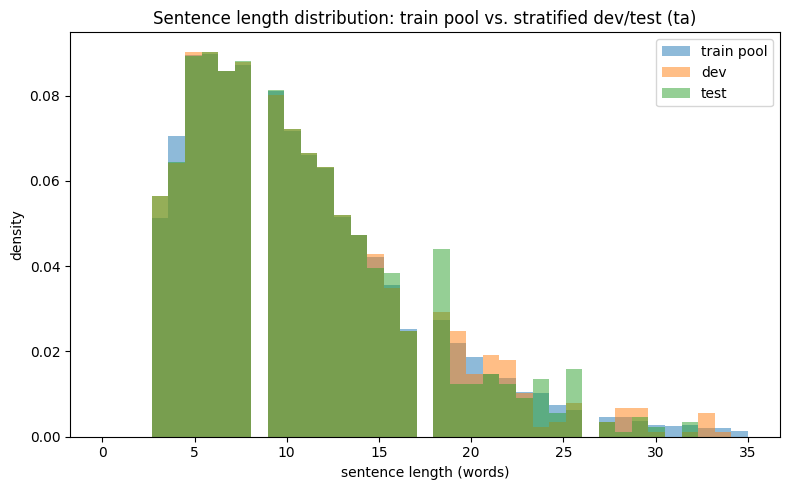

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(0, df_pool["n_words"].quantile(0.99), 40)
ax.hist(train_pool_df["n_words"], bins=bins, alpha=0.5, density=True, label="train pool")
ax.hist(dev_df["n_words"], bins=bins, alpha=0.5, density=True, label="dev")
ax.hist(test_df["n_words"], bins=bins, alpha=0.5, density=True, label="test")
ax.set_xlabel("sentence length (words)")
ax.set_ylabel("density")
ax.set_title(f"Sentence length distribution: train pool vs. stratified dev/test ({LANG})")
ax.legend()
plt.tight_layout()
plt.show()


In [11]:
# save splits to disk (plain text, one sentence per line)
def save_lines(path, texts):
    with open(path, "w", encoding="utf-8") as f:
        for t in texts:
            f.write(t + "\n")

dev_sentences = dev_df["text"].tolist()
test_sentences = test_df["text"].tolist()

save_lines(os.path.join(DATA_DIR, "dev.txt"), dev_sentences)
save_lines(os.path.join(DATA_DIR, "test.txt"), test_sentences)
print("Saved dev.txt and test.txt")


Saved dev.txt and test.txt


## 4. Nested training subsets

The train pool is shuffled once (fixed seed) and then sliced into **nested**
prefixes for each size in `TRAIN_SIZES_RUN`, so the 100k-sentence run is a
strict subset of the 300k run, etc. — isolating the effect of *more data* from
the confound of *different data*.


In [12]:
shuffled_train_pool = train_pool_df["text"].sample(
    frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True).tolist()

max_needed = max(TRAIN_SIZES_RUN)
if len(shuffled_train_pool) < max_needed:
    raise ValueError(
        f"Train pool only has {len(shuffled_train_pool)} sentences but "
        f"{max_needed} were requested by TRAIN_SIZES_RUN. Increase POOL_TARGET "
        f"or lower TRAIN_SIZES_RUN.")

train_subsets = {}
for size in TRAIN_SIZES_RUN:
    subset = shuffled_train_pool[:size]
    train_subsets[size] = subset
    save_lines(os.path.join(DATA_DIR, f"train_{size}.txt"), subset)
    print(f"train size {size:>10,} -> {len(subset):>10,} sentences saved")


train size      2,000 ->      2,000 sentences saved
train size      5,000 ->      5,000 sentences saved
train size      8,000 ->      8,000 sentences saved
train size     12,000 ->     12,000 sentences saved


## 5. Tokenizer training: BPE and WordPiece

We use Hugging Face `tokenizers` — the production Rust implementation of
both **Byte-Pair Encoding** (Sennrich et al., 2016) and **WordPiece**
(Schuster & Nakajima, 2012; used by BERT). Both share the same
normalization (NFC — important for Indic scripts, which can have multiple
Unicode representations of the same visible character) and pre-tokenization
(whitespace + punctuation splitting) so that any downstream differences in
behaviour come from the **subword-merging algorithm itself**, not from
different preprocessing.

A from-scratch, pure-Python BPE trainer (small scale) is included in
§9 to make the merge-learning mechanics explicit.


In [13]:
SPECIAL_TOKENS = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]

def make_pretokenizer():
    return pre_tokenizers.Sequence([
        pre_tokenizers.Whitespace(),
        pre_tokenizers.Punctuation(),
    ])


def train_bpe_tokenizer(sentences, vocab_size):
    tok = Tokenizer(BPE(unk_token="[UNK]"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = make_pretokenizer()
    tok.decoder = decoders.BPEDecoder()
    trainer = BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
                          show_progress=False)
    tok.train_from_iterator(sentences, trainer=trainer)
    return tok


def train_wordpiece_tokenizer(sentences, vocab_size):
    tok = Tokenizer(WordPiece(unk_token="[UNK]"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = make_pretokenizer()
    tok.decoder = decoders.WordPiece()
    trainer = WordPieceTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
                                show_progress=False)
    tok.train_from_iterator(sentences, trainer=trainer)
    return tok


In [14]:
def evaluate_tokenizer(tok, sentences):
    total_tokens = 0
    total_words = 0
    total_chars = 0
    unk_id = tok.token_to_id("[UNK]")
    n_unk = 0
    used_ids = set()

    for s in sentences:
        enc = tok.encode(s)
        ids = enc.ids
        total_tokens += len(ids)
        total_words += len(s.split())
        total_chars += len(s)
        n_unk += sum(1 for i in ids if i == unk_id)
        used_ids.update(ids)

    vocab_size = tok.get_vocab_size()
    return {
        "n_sentences": len(sentences),
        "total_tokens": total_tokens,
        "avg_tokens_per_sentence": total_tokens / len(sentences),
        "fertility_tokens_per_word": total_tokens / total_words,
        "chars_per_token": total_chars / total_tokens,
        "unk_rate_pct": 100.0 * n_unk / total_tokens,
        "vocab_size": vocab_size,
        "vocab_utilization_pct": 100.0 * len(used_ids) / vocab_size,
    }


## 6. Sanity check

Before running the full experiment grid, train both tokenizers once on a
small slice and inspect actual tokenized output on a few dev sentences —
this is the fast correctness check the rest of the notebook's results rely
on.


In [15]:
_sanity_train = train_subsets[min(TRAIN_SIZES_RUN)][:min(3000, min(TRAIN_SIZES_RUN))]
_sanity_vocab = min(2000, min(VOCAB_SIZES_RUN))

_bpe_sanity = train_bpe_tokenizer(_sanity_train, _sanity_vocab)
_wp_sanity = train_wordpiece_tokenizer(_sanity_train, _sanity_vocab)

print(f"Trained sanity BPE / WordPiece on {len(_sanity_train)} sentences, vocab={_sanity_vocab}\n")
for s in dev_sentences[:3]:
    print("SENT :", s[:120])
    print("BPE  :", _bpe_sanity.encode(s).tokens[:25])
    print("WP   :", _wp_sanity.encode(s).tokens[:25])
    print()

print(evaluate_tokenizer(_bpe_sanity, dev_sentences[:200]))
print(evaluate_tokenizer(_wp_sanity, dev_sentences[:200]))


Trained sanity BPE / WordPiece on 2000 sentences, vocab=500

SENT : IPL 2008 பருவத்தில் ஒரு அணி எடுத்த குறைந்தபட்ச ரன்களாக இது அமைந்தது.
BPE  : ['I', 'P', 'L', '2', '00', '8', 'ப', 'ரு', 'வ', 'த்தில்', 'ஒரு', 'அ', 'ணி', 'எ', 'டுத்த', 'கு', 'றை', 'ந்த', 'ப', 'ட்', 'ச', 'ர', 'ன', '்கள', 'ாக']
WP   : ['I', '##P', '##L', '2', '##0', '##0', '##8', 'ப', '##ரு', '##வத', '##்த', '##ில்', 'ஒரு', 'அ', '##ணி', 'எ', '##டுத்த', 'கு', '##றை', '##ந்த', '##ப', '##ட்ச', 'ர', '##ன்', '##க']

SENT : சுமார் 270 கோடி ரூபாயில் உருவாகும் 'புஷ்பா' படத்தின் முதல் பாகம் 2021 ஆகஸ்ட் 13 அன்று வெளியாகிறது.
BPE  : ['சு', 'மா', 'ர்', '2', '7', '0', 'கோ', 'டி', 'ரூ', 'பா', 'ய', 'ில்', 'உ', 'ரு', 'வாக', 'ும்', "'", 'பு', 'ஷ', '்', 'பா', "'", 'பட', 'த்தின்', 'முத']
WP   : ['சு', '##மா', '##ர்', '2', '##7', '##0', 'கோ', '##டி', 'ர', '##ூ', '##ப', '##ாய', '##ில்', 'உ', '##ரு', '##வா', '##கு', '##ம்', "'", 'பு', '##ஷ', '##்', '##ப', '##ா', "'"]

SENT : மறுபுறம், உங்கள் வலைத்தளத்தின் வடிவமைப்பை எவ்வாறு குறியீடு செய்வது என்

## 7. Task 3 — Effect of training-data size

Vocabulary size held fixed at `FIXED_VOCAB_FOR_SIZE_EXPT_RUN`; training size
swept over `TRAIN_SIZES_RUN`. Both tokenizers are evaluated on the same
held-out dev and test sets for every training size.


In [16]:
results_size = []

for size in TRAIN_SIZES_RUN:
    train_sents = train_subsets[size]

    bpe_tok = train_bpe_tokenizer(train_sents, FIXED_VOCAB_FOR_SIZE_EXPT_RUN)
    wp_tok = train_wordpiece_tokenizer(train_sents, FIXED_VOCAB_FOR_SIZE_EXPT_RUN)

    for algo, tok in [("BPE", bpe_tok), ("WordPiece", wp_tok)]:
        for split_name, split_sents in [("dev", dev_sentences), ("test", test_sentences)]:
            m = evaluate_tokenizer(tok, split_sents)
            m.update({"algorithm": algo, "train_size": size, "split": split_name,
                       "vocab_size_target": FIXED_VOCAB_FOR_SIZE_EXPT_RUN})
            results_size.append(m)

    tok_path_bpe = os.path.join(TOK_DIR, f"bpe_size{size}_vocab{FIXED_VOCAB_FOR_SIZE_EXPT_RUN}.json")
    tok_path_wp = os.path.join(TOK_DIR, f"wordpiece_size{size}_vocab{FIXED_VOCAB_FOR_SIZE_EXPT_RUN}.json")
    bpe_tok.save(tok_path_bpe)
    wp_tok.save(tok_path_wp)
    print(f"train_size={size:>10,}  done  (saved {os.path.basename(tok_path_bpe)}, "
          f"{os.path.basename(tok_path_wp)})")

df_size = pd.DataFrame(results_size)
df_size.head()


train_size=     2,000  done  (saved bpe_size2000_vocab1000.json, wordpiece_size2000_vocab1000.json)


train_size=     5,000  done  (saved bpe_size5000_vocab1000.json, wordpiece_size5000_vocab1000.json)


train_size=     8,000  done  (saved bpe_size8000_vocab1000.json, wordpiece_size8000_vocab1000.json)


train_size=    12,000  done  (saved bpe_size12000_vocab1000.json, wordpiece_size12000_vocab1000.json)


,n_sentences,total_tokens,avg_tokens_per_sentence,fertility_tokens_per_word,chars_per_token,unk_rate_pct,vocab_size,vocab_utilization_pct,algorithm,train_size,split,vocab_size_target
0,1000,34177,34.177,3.043095,2.925827,0.084852,1000,97.8,BPE,2000,dev,1000
1,1000,34163,34.163,3.029172,2.935603,0.038053,1000,98.1,BPE,2000,test,1000
2,1000,36729,36.729,3.270323,2.722535,0.073511,1000,93.4,WordPiece,2000,dev,1000
3,1000,36759,36.759,3.259354,2.728284,0.046247,1000,94.0,WordPiece,2000,test,1000
4,1000,34317,34.317,3.055561,2.913891,0.029140,1000,96.3,BPE,5000,dev,1000


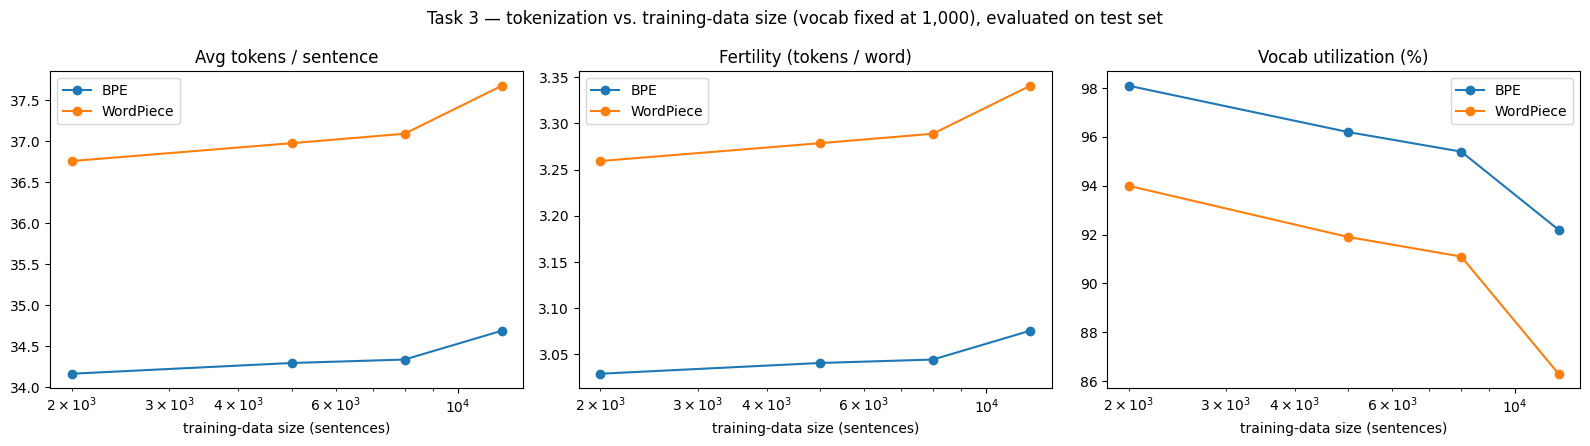

,algorithm,train_size,avg_tokens_per_sentence,fertility_tokens_per_word,unk_rate_pct,vocab_utilization_pct
1,BPE,2000,34.163,3.029172,0.038053,98.1
3,WordPiece,2000,36.759,3.259354,0.046247,94.0
5,BPE,5000,34.294,3.040787,0.023328,96.2
7,WordPiece,5000,36.977,3.278684,0.024339,91.9
9,BPE,8000,34.336,3.044511,0.017474,95.4
11,WordPiece,8000,37.092,3.288881,0.016176,91.1
13,BPE,12000,34.688,3.075723,0.002883,92.2
15,WordPiece,12000,37.678,3.340841,0.002654,86.3


In [17]:
df_size_test = df_size[df_size["split"] == "test"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics = ["avg_tokens_per_sentence", "fertility_tokens_per_word", "vocab_utilization_pct"]
titles = ["Avg tokens / sentence", "Fertility (tokens / word)", "Vocab utilization (%)"]

for ax, metric, title in zip(axes, metrics, titles):
    for algo, grp in df_size_test.groupby("algorithm"):
        grp = grp.sort_values("train_size")
        ax.plot(grp["train_size"], grp[metric], marker="o", label=algo)
    ax.set_xlabel("training-data size (sentences)")
    ax.set_title(title)
    ax.set_xscale("log")
    ax.legend()

plt.suptitle(f"Task 3 — tokenization vs. training-data size (vocab fixed at "
             f"{FIXED_VOCAB_FOR_SIZE_EXPT_RUN:,}), evaluated on test set")
plt.tight_layout()
plt.show()

df_size_test[["algorithm", "train_size", "avg_tokens_per_sentence",
              "fertility_tokens_per_word", "unk_rate_pct", "vocab_utilization_pct"]]


**Expected pattern (fill in / confirm once run at full scale):** as
training-data size grows, both tokenizers see a wider variety of subword
contexts before hitting the vocabulary budget, so they tend to learn more
*efficient*, higher-frequency merges — average tokens/sentence and fertility
typically **decrease and then plateau**, while vocabulary utilization on
held-out data tends to **increase** (fewer learned tokens go unused). The
gap between BPE and WordPiece usually narrows as data grows, since both
converge toward similarly efficient segmentations once there's enough signal
to fill the fixed vocabulary budget well.

*(Run the cell above with `DEBUG = False` and replace this note with your
own observations from the actual 100k/300k/500k/1M-sentence numbers.)*


## 8. Task 4 — Effect of vocabulary size

Training size held fixed at `FIXED_TRAIN_FOR_VOCAB_EXPT_RUN`; vocabulary size
swept over `VOCAB_SIZES_RUN`.


In [18]:
results_vocab = []
_fixed_train_sents = train_subsets.get(FIXED_TRAIN_FOR_VOCAB_EXPT_RUN)
if _fixed_train_sents is None:
    # fall back to the nearest available subset already sliced above
    _fixed_train_sents = shuffled_train_pool[:FIXED_TRAIN_FOR_VOCAB_EXPT_RUN]

for vocab_size in VOCAB_SIZES_RUN:
    bpe_tok = train_bpe_tokenizer(_fixed_train_sents, vocab_size)
    wp_tok = train_wordpiece_tokenizer(_fixed_train_sents, vocab_size)

    for algo, tok in [("BPE", bpe_tok), ("WordPiece", wp_tok)]:
        for split_name, split_sents in [("dev", dev_sentences), ("test", test_sentences)]:
            m = evaluate_tokenizer(tok, split_sents)
            m.update({"algorithm": algo, "vocab_size_target": vocab_size, "split": split_name,
                       "train_size": FIXED_TRAIN_FOR_VOCAB_EXPT_RUN})
            results_vocab.append(m)

    print(f"vocab_size={vocab_size:>8,}  done")

df_vocab = pd.DataFrame(results_vocab)
df_vocab.head()


vocab_size=     500  done


vocab_size=   1,000  done


vocab_size=   2,000  done


,n_sentences,total_tokens,avg_tokens_per_sentence,fertility_tokens_per_word,chars_per_token,unk_rate_pct,vocab_size,vocab_utilization_pct,algorithm,vocab_size_target,split,train_size
0,1000,41601,41.601,3.704123,2.403692,0.021634,500,91.2,BPE,500,dev,8000
1,1000,41676,41.676,3.695336,2.406397,0.014397,500,91.4,BPE,500,test,8000
2,1000,47176,47.176,4.200516,2.119637,0.012718,500,81.8,WordPiece,500,dev,8000
3,1000,47401,47.401,4.202962,2.115757,0.012658,500,83.0,WordPiece,500,test,8000
4,1000,34356,34.356,3.059033,2.910583,0.026196,1000,95.4,BPE,1000,dev,8000


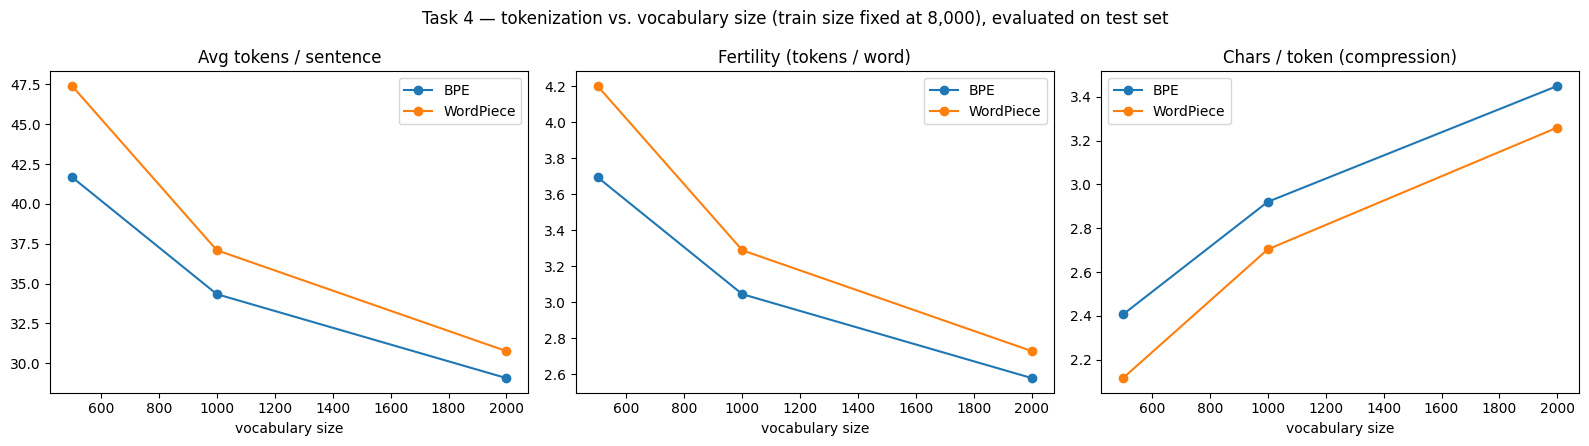

,algorithm,vocab_size_target,avg_tokens_per_sentence,fertility_tokens_per_word,unk_rate_pct,chars_per_token
1,BPE,500,41.676,3.695336,0.014397,2.406397
3,WordPiece,500,47.401,4.202962,0.012658,2.115757
5,BPE,1000,34.336,3.044511,0.017474,2.920812
7,WordPiece,1000,37.092,3.288881,0.016176,2.703791
9,BPE,2000,29.070,2.577585,0.020640,3.449914
11,WordPiece,2000,30.764,2.727789,0.019503,3.259947


In [19]:
df_vocab_test = df_vocab[df_vocab["split"] == "test"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics = ["avg_tokens_per_sentence", "fertility_tokens_per_word", "chars_per_token"]
titles = ["Avg tokens / sentence", "Fertility (tokens / word)", "Chars / token (compression)"]

for ax, metric, title in zip(axes, metrics, titles):
    for algo, grp in df_vocab_test.groupby("algorithm"):
        grp = grp.sort_values("vocab_size_target")
        ax.plot(grp["vocab_size_target"], grp[metric], marker="o", label=algo)
    ax.set_xlabel("vocabulary size")
    ax.set_title(title)
    ax.legend()

plt.suptitle(f"Task 4 — tokenization vs. vocabulary size (train size fixed at "
             f"{FIXED_TRAIN_FOR_VOCAB_EXPT_RUN:,}), evaluated on test set")
plt.tight_layout()
plt.show()

df_vocab_test[["algorithm", "vocab_size_target", "avg_tokens_per_sentence",
               "fertility_tokens_per_word", "unk_rate_pct", "chars_per_token"]]


**Expected pattern (fill in / confirm once run at full scale):** a
larger vocabulary budget lets both algorithms learn longer, more specific
merges, so **average tokens/sentence and fertility decrease** (each token
covers more characters — `chars_per_token` rises) as vocab size grows from
20k → 50k. Returns are usually diminishing: the drop from 20k→30k tends to
be larger than 30k→50k. WordPiece's likelihood-based merge criterion versus
BPE's frequency-based one can produce a visible gap here, especially at
smaller vocabularies.

*(Run the cell above with `DEBUG = False` and replace this note with your
own observations from the actual 20k/30k/50k numbers.)*


## 9. Qualitative comparison

The same dev sentences, tokenized by every (algorithm, vocab size) combination
trained in §8, side by side.


In [20]:
example_sentences = dev_sentences[:5]

rows = []
for vocab_size in VOCAB_SIZES_RUN:
    bpe_tok = train_bpe_tokenizer(_fixed_train_sents, vocab_size)
    wp_tok = train_wordpiece_tokenizer(_fixed_train_sents, vocab_size)
    for sent in example_sentences:
        rows.append({
            "vocab_size": vocab_size,
            "sentence": sent[:60] + ("..." if len(sent) > 60 else ""),
            "BPE_tokens": len(bpe_tok.encode(sent).ids),
            "BPE_example": " | ".join(bpe_tok.encode(sent).tokens[:12]),
            "WordPiece_tokens": len(wp_tok.encode(sent).ids),
            "WordPiece_example": " | ".join(wp_tok.encode(sent).tokens[:12]),
        })

pd.DataFrame(rows)


,vocab_size,sentence,BPE_tokens,BPE_example,WordPiece_tokens,WordPiece_example
0,500,IPL 2008 பருவத்தில் ஒரு அணி எடுத்த குறைந்தபட்ச...,30,I | P | L | 20 | 0 | 8 | ப | ரு | வ | த்தில் |...,32,I | ##P | ##L | 2 | ##0 | ##0 | ##8 | ப | ##ரு...
1,500,சுமார் 270 கோடி ரூபாயில் உருவாகும் 'புஷ்பா' பட...,45,சு | மா | ர் | 2 | 7 | 0 | கோ | டி | ர | ூ | ப...,51,சு | ##மா | ##ர் | 2 | ##7 | ##0 | கோ | ##டி |...
2,500,"மறுபுறம், உங்கள் வலைத்தளத்தின் வடிவமைப்பை எவ்வ...",68,"ம | று | பு | ற | ம் | , | உ | ங்கள் | வ | லை ...",74,"ம | ##று | ##ப | ##ு | ##ற | ##ம் | , | உ | ##..."
3,500,7. முன் அறிமுகம் இல்லாத நபர்களிடமிருந்து வரும்...,43,7 | . | முன் | அறி | மு | கம் | இல் | லா | த |...,49,7 | . | மு | ##ன் | அ | ##றி | ##மு | ##க | ##...
4,500,இவர்களில் பெண்கள் 2317 பேரும் ஆண்கள் 2273 பேரு...,26,இ | வர்கள | ில் | பெ | ண | ்க | ள் | 2 | 3 | 1...,27,இ | ##வர் | ##க | ##ளில் | பெ | ##ண் | ##க | #...
5,1000,IPL 2008 பருவத்தில் ஒரு அணி எடுத்த குறைந்தபட்ச...,26,I | P | L | 20 | 0 | 8 | ப | ரு | வ | த்தில் |...,26,I | ##P | ##L | 20 | ##0 | ##8 | பர | ##ுவ | #...
6,1000,சுமார் 270 கோடி ரூபாயில் உருவாகும் 'புஷ்பா' பட...,37,சு | மார் | 2 | 7 | 0 | கோ | டி | ரூபா | யில் ...,40,சு | ##மா | ##ர் | 2 | ##7 | ##0 | கோ | ##டி |...
7,1000,"மறுபுறம், உங்கள் வலைத்தளத்தின் வடிவமைப்பை எவ்வ...",57,"ம | று | பு | ற | ம் | , | உங்கள் | வ | லை | த...",64,"ம | ##று | ##பு | ##ற | ##ம் | , | உங்கள் | வ ..."
8,1000,7. முன் அறிமுகம் இல்லாத நபர்களிடமிருந்து வரும்...,37,7 | . | முன் | அறி | மு | கம் | இல்லா | த | ந ...,41,7 | . | மு | ##ன் | அறி | ##முக | ##ம் | இல்ல ...
9,1000,இவர்களில் பெண்கள் 2317 பேரும் ஆண்கள் 2273 பேரு...,24,இ | வர்கள | ில் | பெ | ண்க | ள் | 2 | 3 | 1 | ...,24,இ | ##வர்க | ##ளில் | பெ | ##ண் | ##கள் | 2 | ...


## 10. Appendix — from-scratch BPE, for intuition

The library above is what makes the 1M-sentence / 50k-vocab experiments
tractable, but it's worth seeing the actual **merge-learning loop** BPE runs
under the hood. This is a minimal, unoptimized pure-Python implementation
(character-level, whitespace word boundaries, no special tokens) trained on
a small sample purely to show the mechanics — it is *not* used anywhere in
the experiments above.


In [21]:
def word_freqs_from_sentences(sentences):
    freqs = Counter()
    for s in sentences:
        for w in s.split():
            freqs[w] += 1
    return freqs


def get_pair_stats(vocab):
    pairs = Counter()
    for word, freq in vocab.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            pairs[(symbols[i], symbols[i + 1])] += freq
    return pairs


def merge_vocab(pair, vocab):
    bigram = " ".join(pair)
    replacement = "".join(pair)
    new_vocab = {}
    for word, freq in vocab.items():
        new_word = word.replace(bigram, replacement)
        new_vocab[new_word] = freq
    return new_vocab


def train_bpe_from_scratch(sentences, num_merges=60, verbose=True):
    word_freqs = word_freqs_from_sentences(sentences)
    # represent each word as space-separated characters, with </w> as an
    # explicit end-of-word marker
    vocab = {" ".join(list(w)) + " </w>": f for w, f in word_freqs.items()}
    merges = []
    for i in range(num_merges):
        pairs = get_pair_stats(vocab)
        if not pairs:
            break
        best = max(pairs, key=pairs.get)
        vocab = merge_vocab(best, vocab)
        merges.append(best)
        if verbose and i < 10:
            print(f"merge {i+1:2d}: {best[0]!r} + {best[1]!r}  (freq={pairs[best]})")
    return merges, vocab


_scratch_sample = train_subsets[min(TRAIN_SIZES_RUN)][:300]
_merges, _final_vocab = train_bpe_from_scratch(_scratch_sample, num_merges=60)
print(f"\nLearned {len(_merges)} merges from {len(_scratch_sample)} sentences.")
print("Sample resulting word segmentations:")
for w in list(_final_vocab.keys())[:8]:
    print(" -", w)


merge  1: '்' + '</w>'  (freq=1185)
merge  2: '்' + 'க'  (freq=771)
merge  3: '்' + 'த'  (freq=567)
merge  4: 'ு' + '</w>'  (freq=480)
merge  5: 'க' + '்க'  (freq=397)
merge  6: '்' + 'ப'  (freq=381)
merge  7: '.' + '</w>'  (freq=323)
merge  8: '்' + 'ட'  (freq=322)
merge  9: 'ு' + 'ம'  (freq=301)
merge 10: 'த' + '்த'  (freq=295)

Learned 60 merges from 300 sentences.
Sample resulting word segmentations:
 - ஜ ன ந ா ய க த ்</w>
 - த ே வ த ைய ின்</w>
 - ம ூ ச ்ச ு க ்</w>
 - கா ற்ற ு த ான்</w>
 - த ே ர ்த ல்.</w>
 - உ ல க த்தின்</w>
 - மு ன ் ன ோ ட ி</w>
 - த ொ ழ ி ல் ந ு ட ்ப </w>


## 11. Summary

- **Data**: Tamil sentences streamed on demand from `ai4bharat/IndicCorpV2`
  (`data/ta.txt`, ~11.8 GB) via HTTP range requests — no full download —
  sentence-split with the Indic NLP Library, and cleaned (URL/boilerplate
  removal, minimum Tamil-script-character ratio, length bounds).
- **Splits**: dev/test = 1000 sentences each, drawn via **length-stratified**
  sampling (20 quantile buckets on word count) so both splits track the
  corpus's overall length distribution instead of clustering near the mean;
  training subsets of 100k/300k/500k/1M sentences are **nested** prefixes of
  one shuffled pool.
- **Tokenizers**: BPE and WordPiece trained with Hugging Face `tokenizers`
  (shared NFC normalization + whitespace/punctuation pre-tokenization), plus
  a small from-scratch BPE trainer showing the underlying merge loop.
- **Task 3 / Task 4 results**: see §7 and §8 — re-run with `DEBUG = False`
  for the graded, assignment-scale numbers (this notebook as committed ran
  with `DEBUG = True` for fast end-to-end verification).

### Reproducing the full-scale run
1. Set `DEBUG = False` in §1.
2. Kernel → Restart & Run All.
3. Expect: ~1M+ HTTP-streamed lines (a few hundred MB transferred, **not**
   the full 11.8 GB file), then up to 4×2 + 3×2 = 14 tokenizer trainings at
   up to 1,000,000 sentences / 50,000 vocab — budget real wall-clock time for
   this on a laptop-class CPU.
